<a href="https://colab.research.google.com/github/erica-teoh/stargazers-log/blob/main/MMA3001_CO2_Reconstruction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MMA3001 Project — Reconstruction of Missing Indoor CO₂ Sensor Measurements

This project investigates the reconstruction of missing indoor CO₂ sensor measurements using numerical interpolation and machine-learning methods.

The primary engineering question is:

How accurately can missing CO₂ measurements be reconstructed using numerical interpolation and machine-learning methods, and how does reconstruction performance change as the duration of missing data increases?

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import glob
import pandas as pd
import numpy as np
import json

filename = "5EnvSensor_MayToDec2024_180kRows.csv"

matches = glob.glob(
    f"/content/drive/MyDrive/**/{filename}",
    recursive=True
)

print("Files found:")
print(matches)

Files found:
['/content/drive/MyDrive/MMA3001 Project/5EnvSensor_MayToDec2024_180kRows.csv']


In [3]:
file_path = matches[0]

raw_df = pd.read_csv(file_path)

print("Dataset shape:", raw_df.shape)
print("\nColumns:")
print(raw_df.columns.tolist())

raw_df.head()

Dataset shape: (179447, 8)

Columns:
['id', 'sensorid', 'devicetype', 'jsondata', 'status', 'processing_errors', 'createdate', 'processdate']


,id,sensorid,devicetype,jsondata,status,processing_errors,createdate,processdate
0,2,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 03:11:58.210358+11,2024-02-29 03:11:58.210358+11
1,4,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:08.833822+11,2024-02-29 17:09:08.833822+11
2,5,6012002000326,env,"[{""values"": [{""time"": 1702270857, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:12.444245+11,2024-02-29 17:09:12.444245+11
3,16,6012002000777,env,"[{""values"": [{""time"": 1683326565, ""value"": 4.1...",Processed,NaN,2024-02-29 17:10:24.443407+11,2024-02-29 17:10:24.443407+11
4,24,6012002000869,env,"[{""values"": [{""time"": 1709186696, ""value"": 4.1...",Processed,NaN,2024-02-29 17:11:11.348578+11,2024-02-29 17:11:11.348578+11


In [7]:
def unpack_sensor_row(json_string):
    """
    Extract environmental sensor measurements from one JSON record.
    Missing measurements are stored as NaN rather than causing an error.
    """

    data = json.loads(json_string)

    output = {}
    measurement_times = []

    for item in data:

        variable_name = item["variable"]["name"]
        values = item.get("values", [])

        if len(values) > 0:

            # Some entries contain a timestamp but no measurement value
            output[variable_name] = values[0].get("value", np.nan)

            if "time" in values[0]:
                measurement_times.append(values[0]["time"])

    if measurement_times:
        output["measurement_time"] = measurement_times[0]

    return output


parsed_measurements = pd.DataFrame(
    raw_df["jsondata"]
    .apply(unpack_sensor_row)
    .tolist()
)

parsed_measurements["sensorid"] = raw_df["sensorid"].values

parsed_measurements.head()

,Battery,Carbon dioxide,Humidity,Formaldehyde,Pressure,Temperature,Light Volatile Organic Compounds,Particulate matter 1,Particulate matter 4,Particulate matter 2.5,Particulate matter 10,measurement_time,sensorid
0,4.1875,603,66,6.0,1011,23.8,14.0,8.0,9.0,9.0,9.0,1702273965,6012002000241
1,4.1875,603,66,6.0,1011,23.8,14.0,8.0,9.0,9.0,9.0,1702273965,6012002000241
2,4.1875,525,68,5.0,1012,23.8,7.0,6.0,6.0,6.0,6.0,1702270857,6012002000326
3,4.1562,425,51,1.0,1015,18.8,71.0,1.0,3.0,3.0,4.0,1683326565,6012002000777
4,4.1250,465,56,17.0,1010,24.3,0.0,2.0,2.0,2.0,2.0,1709186696,6012002000869


In [8]:
sensor_counts = parsed_measurements["sensorid"].value_counts()

print(sensor_counts)

sensorid
6012002000326    58909
6012002000241    58908
6012002000869    29341
6012002000227    21363
6012002000777    10926
Name: count, dtype: int64


In [9]:
#isolate chosen sensor

SENSOR_ID = 6012002000869

sensor_df = parsed_measurements[
    parsed_measurements["sensorid"] == SENSOR_ID
].copy()

sensor_df["timestamp"] = pd.to_datetime(
    sensor_df["measurement_time"],
    unit="s",
    utc=True
)

sensor_df["timestamp"] = sensor_df["timestamp"].dt.tz_convert(
    "Australia/Melbourne"
)

sensor_df = sensor_df.sort_values("timestamp")

print("Raw rows for selected sensor:", len(sensor_df))
print("Start:", sensor_df["timestamp"].min())
print("End:", sensor_df["timestamp"].max())

sensor_df.head()

Raw rows for selected sensor: 29341
Start: 2024-02-29 17:04:56+11:00
End: 2024-06-14 03:45:44+10:00


,Battery,Carbon dioxide,Humidity,Formaldehyde,Pressure,Temperature,Light Volatile Organic Compounds,Particulate matter 1,Particulate matter 4,Particulate matter 2.5,Particulate matter 10,measurement_time,sensorid,timestamp
4,4.125,465,56,17.0,1010,24.3,0.0,2.0,2.0,2.0,2.0,1709186696,6012002000869,2024-02-29 17:04:56+11:00
8,4.125,445,56,17.0,1010,24.0,0.0,2.0,5.0,4.0,5.0,1709187297,6012002000869,2024-02-29 17:14:57+11:00
12,4.125,471,56,17.0,1010,23.8,0.0,1.0,2.0,2.0,2.0,1709188497,6012002000869,2024-02-29 17:34:57+11:00
16,4.125,457,56,17.0,1010,23.8,0.0,1.0,2.0,2.0,3.0,1709189097,6012002000869,2024-02-29 17:44:57+11:00
20,4.125,455,57,17.0,1010,23.8,0.0,1.0,2.0,2.0,2.0,1709189697,6012002000869,2024-02-29 17:54:57+11:00


In [10]:
#removing duplicate timestamps

clean_df = sensor_df.drop_duplicates(
    subset="measurement_time",
    keep="first"
).copy()

clean_df = clean_df.sort_values("timestamp").reset_index(drop=True)

print("Rows before duplicate removal:", len(sensor_df))
print("Rows after duplicate removal:", len(clean_df))
print("Duplicates removed:", len(sensor_df) - len(clean_df))

print("\nDate range:")
print(clean_df["timestamp"].min())
print("to")
print(clean_df["timestamp"].max())

Rows before duplicate removal: 29341
Rows after duplicate removal: 13800
Duplicates removed: 15541

Date range:
2024-02-29 17:04:56+11:00
to
2024-06-14 03:45:44+10:00


In [11]:
time_difference = clean_df["timestamp"].diff()

interval_minutes = time_difference.dt.total_seconds() / 60

print(interval_minutes.describe())

print("\nMost common sampling intervals:")
print(interval_minutes.round().value_counts().head(10))

count    13799.000000
mean        11.008102
std          3.013253
min          9.566667
25%         10.000000
50%         10.000000
75%         10.000000
max         29.983333
Name: timestamp, dtype: float64

Most common sampling intervals:
timestamp
10.0    12409
20.0     1389
30.0        1
Name: count, dtype: int64


In [12]:
print("Missing CO2 values:")
print(clean_df["Carbon dioxide"].isna().sum())

print("\nCO2 summary:")
print(clean_df["Carbon dioxide"].describe())

Missing CO2 values:
0

CO2 summary:
count    13800.000000
mean       473.985217
std         39.403080
min        403.000000
25%        444.000000
50%        463.000000
75%        494.000000
max        646.000000
Name: Carbon dioxide, dtype: float64


## Stage 2 — Exploratory Data Analysis

In [13]:
print("Clean dataset shape:", clean_df.shape)

print("\nCO2 statistics:")
print(clean_df["Carbon dioxide"].describe())

print("\nMissing values:")
print(clean_df.isna().sum())

Clean dataset shape: (13800, 14)

CO2 statistics:
count    13800.000000
mean       473.985217
std         39.403080
min        403.000000
25%        444.000000
50%        463.000000
75%        494.000000
max        646.000000
Name: Carbon dioxide, dtype: float64

Missing values:
Battery                             0
Carbon dioxide                      0
Humidity                            0
Formaldehyde                        1
Pressure                            0
Temperature                         0
Light Volatile Organic Compounds    0
Particulate matter 1                0
Particulate matter 4                0
Particulate matter 2.5              0
Particulate matter 10               0
measurement_time                    0
sensorid                            0
timestamp                           0
dtype: int64


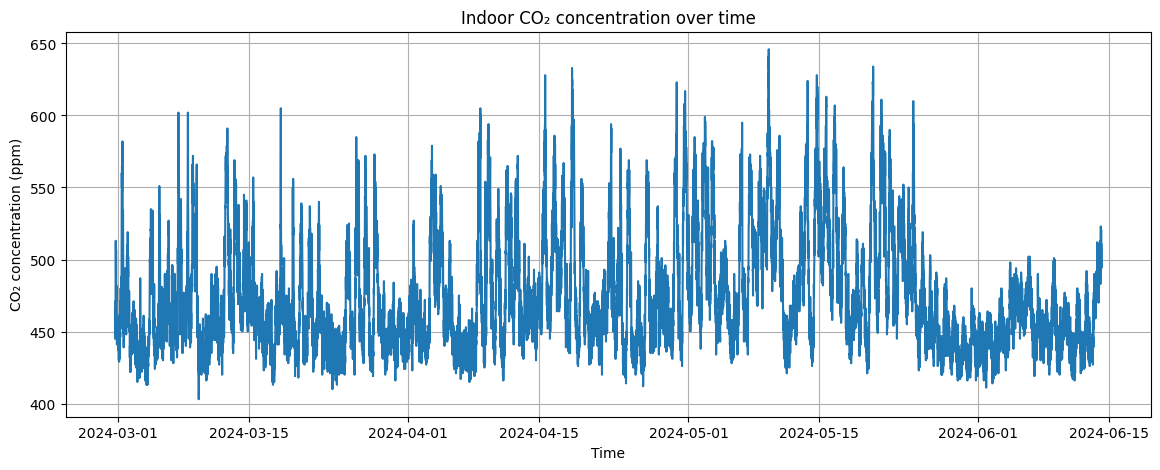

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(clean_df["timestamp"], clean_df["Carbon dioxide"])

plt.xlabel("Time")
plt.ylabel("CO₂ concentration (ppm)")
plt.title("Indoor CO₂ concentration over time")

plt.grid(True)
plt.show()

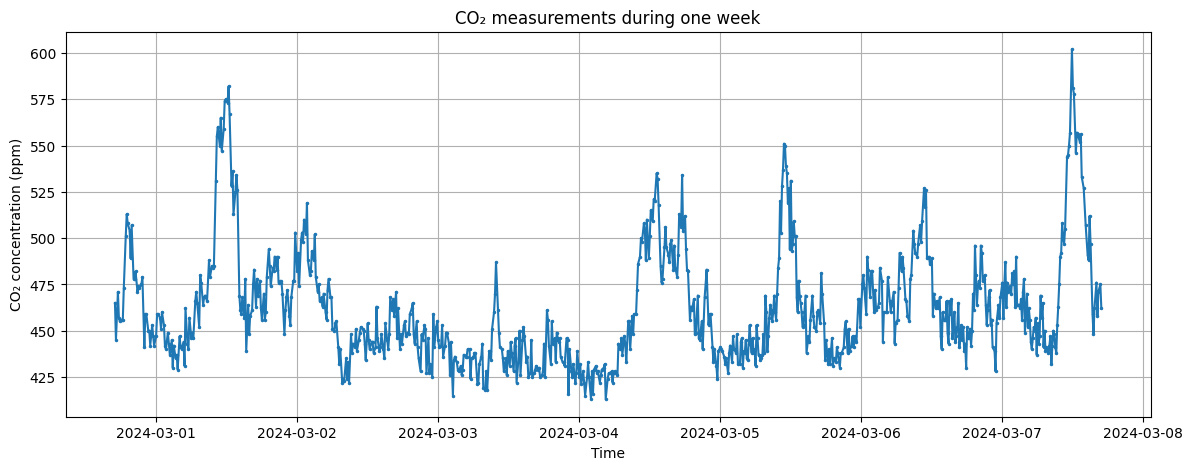

In [15]:
week_start = clean_df["timestamp"].min()
week_end = week_start + pd.Timedelta(days=7)

week_df = clean_df[
    (clean_df["timestamp"] >= week_start) &
    (clean_df["timestamp"] <= week_end)
]

plt.figure(figsize=(14, 5))
plt.plot(
    week_df["timestamp"],
    week_df["Carbon dioxide"],
    marker=".",
    markersize=3
)

plt.xlabel("Time")
plt.ylabel("CO₂ concentration (ppm)")
plt.title("CO₂ measurements during one week")

plt.grid(True)
plt.show()

In [16]:
interval_minutes = (
    clean_df["timestamp"]
    .diff()
    .dt.total_seconds()
    / 60
)

print("Sampling interval statistics:")
print(interval_minutes.describe())

print("\nMost common sampling intervals:")
print(interval_minutes.round().value_counts().head(10))

Sampling interval statistics:
count    13799.000000
mean        11.008102
std          3.013253
min          9.566667
25%         10.000000
50%         10.000000
75%         10.000000
max         29.983333
Name: timestamp, dtype: float64

Most common sampling intervals:
timestamp
10.0    12409
20.0     1389
30.0        1
Name: count, dtype: int64


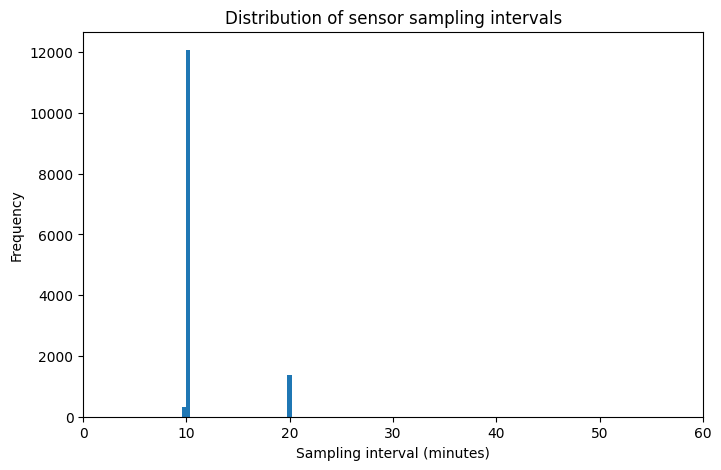

In [17]:
plt.figure(figsize=(8, 5))

plt.hist(
    interval_minutes.dropna(),
    bins=50
)

plt.xlabel("Sampling interval (minutes)")
plt.ylabel("Frequency")
plt.title("Distribution of sensor sampling intervals")

plt.xlim(0, 60)

plt.show()

In [18]:
numeric_columns = [
    "Carbon dioxide",
    "Temperature",
    "Humidity",
    "Pressure",
    "Light Volatile Organic Compounds",
    "Particulate matter 1",
    "Particulate matter 2.5",
    "Particulate matter 4",
    "Particulate matter 10"
]

correlations = (
    clean_df[numeric_columns]
    .corr()["Carbon dioxide"]
    .sort_values(ascending=False)
)

print(correlations)

Carbon dioxide                      1.000000
Pressure                            0.304985
Temperature                         0.170572
Light Volatile Organic Compounds    0.042331
Humidity                            0.010713
Particulate matter 1               -0.075531
Particulate matter 2.5             -0.078499
Particulate matter 4               -0.079480
Particulate matter 10              -0.079563
Name: Carbon dioxide, dtype: float64


### Preliminary EDA observations

The cleaned dataset contains 13,800 CO₂ observations with no missing CO₂ measurements. CO₂ concentration ranges from 403 to 646 ppm, with a mean of approximately 474 ppm.

The sensor is sampled predominantly at approximately 10-minute intervals, although approximately 20-minute intervals also occur. This irregularity will be considered when constructing artificial missing-data gaps.

The CO₂ time series exhibits both relatively smooth periods and rapid transient peaks. This suggests that interpolation may perform well for short, smooth gaps but may struggle when missing intervals contain rapid changes.

Linear correlations between CO₂ and the other environmental variables are generally weak. Pressure shows the strongest positive correlation (approximately 0.305), followed by temperature (approximately 0.171). Therefore, machine-learning methods will be evaluated empirically rather than assuming that the environmental variables provide strong predictive information.

## Stage 3 — Experimental Design and Artificial Missing-Data Gaps

In [20]:
# Use the first 70% of the time series for ML model development
# and the final 30% for reconstruction experiments.

split_index = int(0.70 * len(clean_df))

train_df = clean_df.iloc[:split_index].copy()

evaluation_df = (
    clean_df.iloc[split_index:]
    .copy()
    .reset_index()
    .rename(columns={"index": "original_index"})
)

print("Training observations:", len(train_df))
print("Evaluation observations:", len(evaluation_df))

print("\nTraining period:")
print(train_df["timestamp"].min(), "to", train_df["timestamp"].max())

print("\nEvaluation period:")
print(evaluation_df["timestamp"].min(), "to", evaluation_df["timestamp"].max())

Training observations: 9660
Evaluation observations: 4140

Training period:
2024-02-29 17:04:56+11:00 to 2024-05-14 08:55:31+10:00

Evaluation period:
2024-05-14 09:05:31+10:00 to 2024-06-14 03:45:44+10:00


In [21]:
evaluation_df["interval_minutes"] = (
    evaluation_df["timestamp"]
    .diff()
    .dt.total_seconds()
    / 60
)

# Treat intervals from 9 to 11 minutes as nominal 10-minute sampling
evaluation_df["regular_interval"] = (
    evaluation_df["interval_minutes"]
    .between(9, 11)
)

print(evaluation_df["regular_interval"].value_counts())

print(
    "\nPercentage of evaluation intervals approximately 10 minutes:",
    100 * evaluation_df["regular_interval"].mean()
)

regular_interval
True     3846
False     294
Name: count, dtype: int64

Percentage of evaluation intervals approximately 10 minutes: 92.89855072463769


In [28]:
import numpy as np
import pandas as pd
# Gap lengths expressed as number of expected 10-minute measurements
GAP_SIZES = {
    10: 1,
    30: 3,
    60: 6,
    120: 12
}

N_TRIALS = 100
RANDOM_SEED = 3001

rng = np.random.default_rng(RANDOM_SEED)

# Find locations capable of supporting the LONGEST gap.
# These locations will then be used for every gap duration.

max_missing = max(GAP_SIZES.values())

common_valid_starts = []

for start in range(1, len(evaluation_df) - max_missing):

    end = start + max_missing - 1

    required_edges = evaluation_df.loc[
        start:end + 1,
        "regular_interval"
    ]

    if required_edges.all():
        common_valid_starts.append(start)


print(
    "Locations suitable for every gap duration:",
    len(common_valid_starts)
)

if len(common_valid_starts) < N_TRIALS:
    raise ValueError("Not enough common locations for the experiment.")


# Same 100 locations used for every method and every gap duration
selected_starts = rng.choice(
    common_valid_starts,
    size=N_TRIALS,
    replace=False
)


gap_trials = []

for gap_minutes, n_missing in GAP_SIZES.items():

    for trial_number, start in enumerate(selected_starts, start=1):

        end = start + n_missing - 1

        gap_trials.append({
            "trial": trial_number,
            "gap_minutes": gap_minutes,
            "n_missing": n_missing,
            "start_position": int(start),
            "end_position": int(end),
            "start_time": evaluation_df.loc[start, "timestamp"],
            "end_time": evaluation_df.loc[end, "timestamp"]
        })


gap_trials = pd.DataFrame(gap_trials)

print("\nTotal experiments:", len(gap_trials))

print("\nExperiments by gap duration:")
print(
    gap_trials["gap_minutes"]
    .value_counts()
    .sort_index()
)

gap_trials.head()

Locations suitable for every gap duration: 338

Total experiments: 400

Experiments by gap duration:
gap_minutes
10     100
30     100
60     100
120    100
Name: count, dtype: int64


,trial,gap_minutes,n_missing,start_position,end_position,start_time,end_time
0,1,10,1,3364,3364,2024-06-08 09:45:42+10:00,2024-06-08 09:45:42+10:00
1,2,10,1,2314,2314,2024-05-31 14:35:35+10:00,2024-05-31 14:35:35+10:00
2,3,10,1,1262,1262,2024-05-23 19:15:34+10:00,2024-05-23 19:15:34+10:00
3,4,10,1,1277,1277,2024-05-23 21:55:35+10:00,2024-05-23 21:55:35+10:00
4,5,10,1,1570,1570,2024-05-26 02:05:35+10:00,2024-05-26 02:05:35+10:00


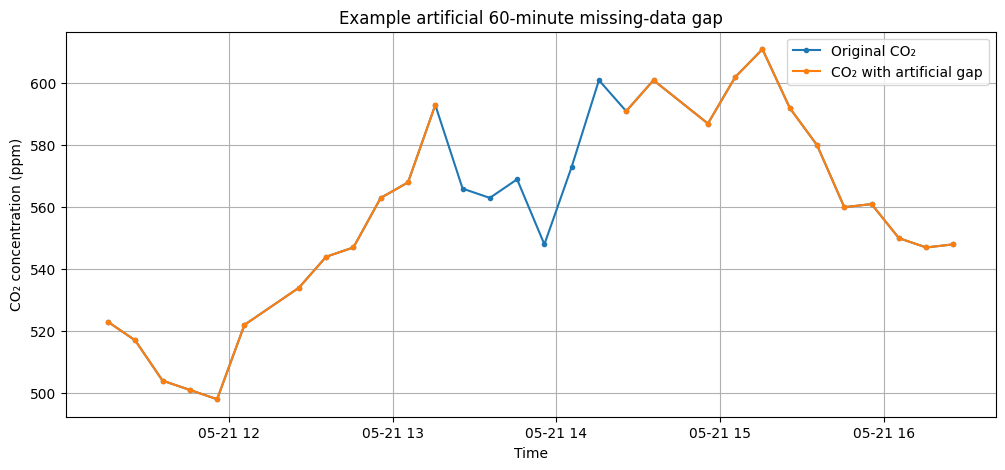

In [23]:
example_trial = gap_trials[
    gap_trials["gap_minutes"] == 60
].iloc[0]

start = int(example_trial["start_position"])
end = int(example_trial["end_position"])

example_df = evaluation_df.copy()

# Save the true values
true_values = example_df.loc[
    start:end,
    "Carbon dioxide"
].copy()

# Artificially remove them
example_df.loc[
    start:end,
    "Carbon dioxide"
] = np.nan


plot_start = max(0, start - 12)
plot_end = min(len(example_df) - 1, end + 12)

plt.figure(figsize=(12, 5))

plt.plot(
    evaluation_df.loc[plot_start:plot_end, "timestamp"],
    evaluation_df.loc[plot_start:plot_end, "Carbon dioxide"],
    label="Original CO₂",
    marker="."
)

plt.plot(
    example_df.loc[plot_start:plot_end, "timestamp"],
    example_df.loc[plot_start:plot_end, "Carbon dioxide"],
    label="CO₂ with artificial gap",
    marker="."
)

plt.xlabel("Time")
plt.ylabel("CO₂ concentration (ppm)")
plt.title("Example artificial 60-minute missing-data gap")

plt.legend()
plt.grid(True)

plt.show()

## Stage 4 — Linear interpolation baseline

In [24]:
from time import perf_counter

linear_predictions = []

for _, trial in gap_trials.iterrows():

    start = int(trial["start_position"])
    end = int(trial["end_position"])

    # Create time-indexed CO2 series
    co2_series = pd.Series(
        evaluation_df["Carbon dioxide"].to_numpy(),
        index=evaluation_df["timestamp"]
    )

    # Ground-truth values before masking
    true_values = co2_series.iloc[start:end + 1].copy()

    # Artificially remove the chosen measurements
    masked_series = co2_series.copy()
    masked_series.iloc[start:end + 1] = np.nan

    # Time the reconstruction method
    start_timer = perf_counter()

    reconstructed = masked_series.interpolate(
        method="time",
        limit_area="inside"
    )

    runtime = perf_counter() - start_timer

    predicted_values = reconstructed.iloc[start:end + 1]

    # Store every hidden point
    for true_value, predicted_value in zip(
        true_values,
        predicted_values
    ):
        linear_predictions.append({
            "trial": int(trial["trial"]),
            "gap_minutes": int(trial["gap_minutes"]),
            "true_co2": true_value,
            "predicted_co2": predicted_value,
            "runtime_seconds": runtime
        })


linear_results = pd.DataFrame(linear_predictions)

linear_results.head()

,trial,gap_minutes,true_co2,predicted_co2,runtime_seconds
0,1,10,440,436.494167,0.002565
1,2,10,431,444.000000,0.001029
2,3,10,466,462.000000,0.000981
3,4,10,432,452.500000,0.000636
4,5,10,602,599.000000,0.000596


In [25]:
def calculate_metrics(group):
    true = group["true_co2"].to_numpy()
    predicted = group["predicted_co2"].to_numpy()

    errors = true - predicted

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors**2))

    ss_res = np.sum(errors**2)
    ss_tot = np.sum((true - np.mean(true))**2)

    r2 = 1 - ss_res / ss_tot

    return pd.Series({
        "MAE_ppm": mae,
        "RMSE_ppm": rmse,
        "R2": r2
    })


linear_metrics = (
    linear_results
    .groupby("gap_minutes")
    .apply(calculate_metrics)
)

print(linear_metrics)

              MAE_ppm   RMSE_ppm        R2
gap_minutes                               
10           8.104629  10.454896  0.933078
30           8.258715  10.553756  0.918475
60           8.349944  10.567786  0.922973
120          8.357763  10.580500  0.832723


/tmp/ipykernel_1823/1638611515.py:25: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calculate_metrics)


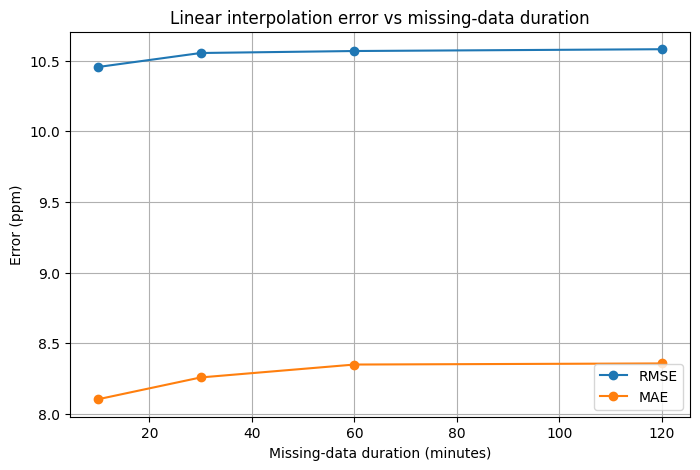

In [26]:
plt.figure(figsize=(8, 5))

plt.plot(
    linear_metrics.index,
    linear_metrics["RMSE_ppm"],
    marker="o",
    label="RMSE"
)

plt.plot(
    linear_metrics.index,
    linear_metrics["MAE_ppm"],
    marker="o",
    label="MAE"
)

plt.xlabel("Missing-data duration (minutes)")
plt.ylabel("Error (ppm)")
plt.title("Linear interpolation error vs missing-data duration")

plt.legend()
plt.grid(True)

plt.show()

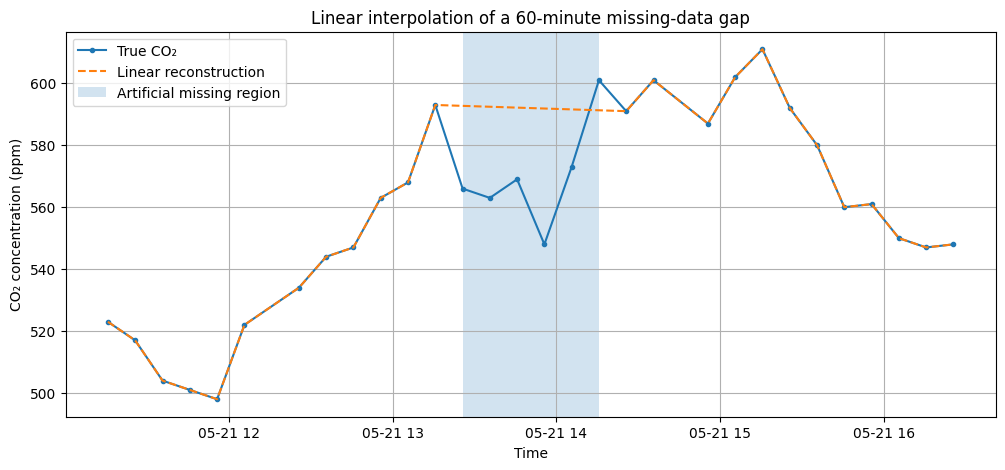

In [27]:
trial_60 = gap_trials[
    gap_trials["gap_minutes"] == 60
].iloc[0]

start = int(trial_60["start_position"])
end = int(trial_60["end_position"])

co2_series = pd.Series(
    evaluation_df["Carbon dioxide"].to_numpy(),
    index=evaluation_df["timestamp"]
)

masked_series = co2_series.copy()
masked_series.iloc[start:end + 1] = np.nan

linear_reconstruction = masked_series.interpolate(
    method="time",
    limit_area="inside"
)

plot_start = max(0, start - 12)
plot_end = min(len(evaluation_df) - 1, end + 12)

plt.figure(figsize=(12, 5))

plt.plot(
    co2_series.index[plot_start:plot_end + 1],
    co2_series.iloc[plot_start:plot_end + 1],
    label="True CO₂",
    marker="."
)

plt.plot(
    linear_reconstruction.index[plot_start:plot_end + 1],
    linear_reconstruction.iloc[plot_start:plot_end + 1],
    label="Linear reconstruction",
    linestyle="--"
)

plt.axvspan(
    evaluation_df.loc[start, "timestamp"],
    evaluation_df.loc[end, "timestamp"],
    alpha=0.2,
    label="Artificial missing region"
)

plt.xlabel("Time")
plt.ylabel("CO₂ concentration (ppm)")
plt.title("Linear interpolation of a 60-minute missing-data gap")

plt.legend()
plt.grid(True)

plt.show()